# 07 · Figures and tables for the paper

This notebook makes the six figures and two tables used in the paper. It adds no new analysis: every number comes from the result files that notebooks 04, 05 and 06 saved in `results/`, plus two models refitted with the settings notebook 04 chose (needed to draw the error map and the height effect).

It runs from the small files in the repo in about a minute. Figures go to `figures/paper_fig*.png` and tables to `results/paper_table*.csv`.

| output | shows | paper section |
|---|---|---|
| Figure 1 | the flood label in the three seasons | 2 |
| Figure 2 | the regions and the two validation schemes | 3 |
| Figure 3 | skill for every held-out season and region | 4 |
| Figure 4 | what the forest uses, and the effect of height | 5 |
| Figure 5 | 2026: observed, usual, and where the forest was right or wrong | 5 |
| Figure 6 | season totals under the original and the equal-coverage label | 6 |
| Table 1 | skill per fold for every method | 4 |
| Table 2 | every stress test in one line | 4 to 6 |

## Setup

One look for all figures: the same four colours in the same order, light grid lines, and text in dark grey.

In [1]:
import sys, ast, warnings
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from config import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import partial_dependence

warnings.filterwarnings("ignore")
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"      # checked for colour-blind safety
MORE = ["#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID, PALE = "#0b0b0b", "#52514e", "#e4e3df", "#d9d8d3"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.titlecolor": INK, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
                     "figure.facecolor": "white", "savefig.dpi": 300, "savefig.bbox": "tight", "legend.frameon": False})
LABEL, EVENT = "flooded_frac", 0.05

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png"); print("saved", f"figures/{name}.png")
def clean_map(ax, title):
    ax.set_title(title); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)

df = pd.read_parquet(SMALL_DIR / "model_table.parquet")
FEATURES = pd.read_csv(RESULTS_DIR / "feature_dictionary.csv")["feature"].tolist()
piv = df.pivot(index="cell_id", columns="season", values=LABEL)

def make_regions(cells, level="basin_l5", min_size=300):        # same regions as notebook 04
    c = cells.groupby(level).agg(n=("cell_id", "size"), lat=("lat", "mean"), lon=("lon", "mean"))
    big = c[c.n >= min_size]
    if len(big) < 3: big = c.nlargest(3, "n")
    mapping = {}
    for b, r in c.iterrows():
        d = (big.lat - r.lat) ** 2 + ((big.lon - r.lon) * np.cos(np.radians(r.lat))) ** 2
        mapping[b] = b if b in big.index else d.idxmin()
    names = {b: f"R{i + 1}" for i, b in enumerate(big.sort_values(["lon", "lat"]).index)}
    return cells[level].map(mapping).map(names)
cells = df[df.season == YEARS[0]][["cell_id", "lat", "lon", "basin_l5"]].reset_index(drop=True)
cells["basin_l5"] = cells["basin_l5"].astype(int)
cells["region"] = make_regions(cells)
df = df.merge(cells[["cell_id", "region"]], on="cell_id")
REGIONS = sorted(cells.region.unique(), key=lambda r: int(r[1:]))
REG_COL = dict(zip(REGIONS, [BLUE, ORANGE, AQUA, YELLOW] + MORE))

tc = pd.read_csv(RESULTS_DIR / "tuning_choices.csv"); tc["fold"] = tc["fold"].astype(str)
def forest_for(scheme, fold):
    p = ast.literal_eval(tc[(tc.scheme == scheme) & (tc.fold == str(fold)) & (tc.model == "forest")]["best"].iloc[0])
    return RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, **p)
print(df.shape, REGIONS)

(11922, 39) ['R1', 'R2', 'R3', 'R4']


## Figure 1 · The flood label in three seasons

Grey is the study area (squares photographed at least 5 times in every season). Blue is the share of each 5 km square that was underwater, after removing permanent water.

saved figures/paper_fig1_label_maps.png


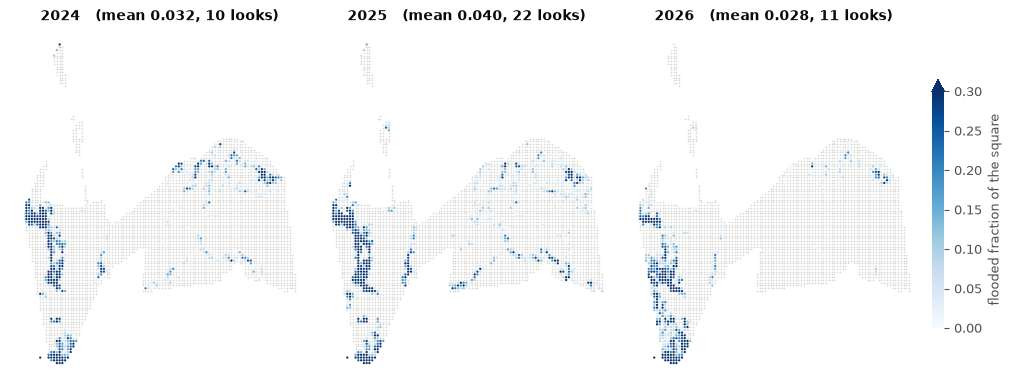

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(10, 4.6), layout="constrained")
for a, y in zip(ax, YEARS):
    t = df[df.season == y]
    a.scatter(t.lon, t.lat, c=PALE, s=1.5, linewidths=0)
    w = t[t[LABEL] > 0].sort_values(LABEL)
    sc = a.scatter(w.lon, w.lat, c=w[LABEL], s=2.5, cmap="Blues", vmin=0, vmax=0.3, linewidths=0)
    clean_map(a, f"{y}   (mean {t[LABEL].mean():.3f}, {t.times_photographed.mean():.0f} looks)")
cb = fig.colorbar(sc, ax=ax, shrink=0.55, pad=0.01, extend="max"); cb.set_label("flooded fraction of the square"); cb.outline.set_visible(False)
save(fig, "paper_fig1_label_maps"); plt.show()

## Figure 2 · The regions and the two validation schemes

Left: the four river-basin regions. Right: what is held out in each scheme. Each small box is one region in one season; dark boxes are the test data, light boxes the training data.

saved figures/paper_fig2_validation.png


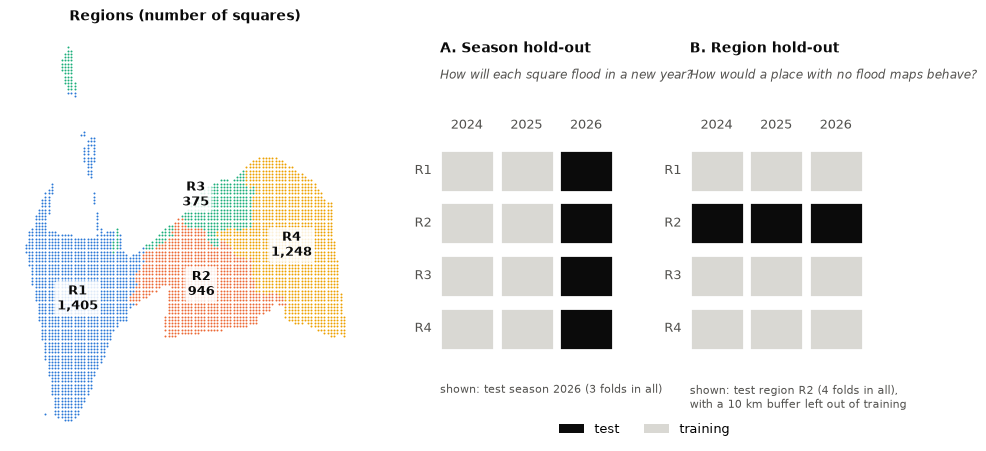

In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 4.4), layout="constrained", gridspec_kw={"width_ratios": [1, 1.25]})
for r in REGIONS:
    t = cells[cells.region == r]
    a.scatter(t.lon, t.lat, s=2, color=REG_COL[r], linewidths=0)
    a.text(t.lon.mean(), t.lat.mean(), f"{r}\n{len(t):,}", ha="center", va="center", fontsize=9, color=INK, fontweight="bold",
           bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
clean_map(a, "Regions (number of squares)")

def scheme(ax, x0, title, question, test):
    ax.text(x0, 5.75, title, fontweight="bold", color=INK, fontsize=10)
    ax.text(x0, 5.25, question, color=MUTED, fontsize=8.5, style="italic")
    for i, r in enumerate(REGIONS[:4]):
        ax.text(x0 - 0.15, 3.5 - i, r, ha="right", va="center", color=MUTED)
        for j, y in enumerate(YEARS):
            ax.add_patch(Rectangle((x0 + j * 1.05, 3.1 - i), 0.95, 0.8, fc=INK if test(r, y) else PALE, ec="white", lw=2))
    for j, y in enumerate(YEARS):
        ax.text(x0 + j * 1.05 + 0.47, 4.3, str(y), ha="center", color=MUTED)
scheme(b, 0.6, "A. Season hold-out", "How will each square flood in a new year?", lambda r, y: y == YEARS[-1])
scheme(b, 5.0, "B. Region hold-out", "How would a place with no flood maps behave?", lambda r, y: r == REGIONS[1])
b.text(0.6, -0.55, f"shown: test season {YEARS[-1]} (3 folds in all)", color=MUTED, fontsize=8, va="top")
b.text(5.0, -0.55, f"shown: test region {REGIONS[1]} ({len(REGIONS)} folds in all),\nwith a 10 km buffer left out of training", color=MUTED, fontsize=8, va="top")
b.legend(handles=[Rectangle((0, 0), 1, 1, fc=INK), Rectangle((0, 0), 1, 1, fc=PALE)], labels=["test", "training"],
         loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))
b.set_xlim(-0.2, 8.6); b.set_ylim(-1.6, 6.2); b.axis("off")
save(fig, "paper_fig2_validation"); plt.show()

## Table 1 and Figure 3 · Skill for every held-out season and region

Skill = 1 − (model error ÷ reference error), using squared errors. **0 means no better than the reference**, 1 is perfect, below 0 is worse. The reference is *usual* (the square's average in the other seasons) for the season hold-out, and *one constant* for the region hold-out, where no flood history exists.

In a mostly dry region "never flooded" is a better simple guess than one constant. So Table 1b ends with one extra line: the forest measured against **the best simple baseline in each region** (the best of never flooded, one constant and the elevation line, picked on the test region). This is the honest size of the gain.

In [4]:
sc = pd.read_csv(RESULTS_DIR / "scores_by_fold.csv"); sc["fold"] = sc["fold"].astype(str)
x1 = pd.read_csv(RESULTS_DIR / "x1_history_matched.csv").set_index("method")
x4 = pd.read_csv(RESULTS_DIR / "x4_boosting.csv"); x4["fold"] = x4["fold"].astype(str)

def wide(scheme, methods):
    return sc[(sc.scheme == scheme) & sc.method.isin(methods)].pivot(index="method", columns="fold", values="skill").loc[methods]
A = wide("A season", ["never", "constant", "elevation", "usual", "ridge", "forest"])
A.loc["usual x one number"] = x1.loc["shrunken usual"].values
A.loc["boosting + physics"] = x4[x4.scheme.str.startswith("A") & (x4.method == "boosting + physics")].set_index("fold").skill.reindex(A.columns).values
B = wide("B region", ["never", "constant", "elevation", "ridge", "forest"])
B.loc["boosting + physics"] = x4[x4.scheme.str.startswith("B") & (x4.method == "boosting + physics")].set_index("fold").skill.reindex(B.columns).values
rB = sc[sc.scheme == "B region"].pivot(index="method", columns="fold", values="RMSE")
best_simple = rB.loc[["never", "constant", "elevation"]].idxmin()            # best simple baseline in each region
B.loc["random forest vs best simple baseline"] = (1 - (rB.loc["forest"] / rB.loc[["never", "constant", "elevation"]].min()) ** 2).reindex(B.columns).values
names = {"never": "never flooded", "constant": "one constant", "elevation": "elevation only (linear)", "usual": "usual (persistence)",
         "ridge": "ridge regression", "forest": "random forest"}
A, B = A.rename(index=names).round(2), B.rename(index=names).round(2)
A.to_csv(RESULTS_DIR / "paper_table1a_season_skill.csv"); B.to_csv(RESULTS_DIR / "paper_table1b_region_skill.csv")
print("Table 1a. Season hold-out: skill against usual, one column per held-out season"); display(A)
print("Table 1b. Region hold-out: skill against one constant, one column per held-out region (last line: against the best simple baseline)"); display(B)
print("Best simple baseline in each region:", best_simple.to_dict())

Table 1a. Season hold-out: skill against usual, one column per held-out season


fold,2024,2025,2026
method,,,
never flooded,-3.60,-4.11,-0.96
one constant,-3.21,-3.61,-0.83
elevation only (linear),-2.91,-3.27,-0.66
usual (persistence),0.00,0.00,0.00
ridge regression,-0.14,-0.34,0.06
random forest,-0.42,-0.38,0.12
usual x one number,-0.06,-0.44,0.12
boosting + physics,-0.28,-0.41,0.05


Table 1b. Region hold-out: skill against one constant, one column per held-out region (last line: against the best simple baseline)


fold,R1,R2,R3,R4
method,,,,
never flooded,-0.06,0.55,-0.03,0.19
one constant,0.00,0.00,0.00,0.00
elevation only (linear),0.04,0.28,0.09,-0.06
ridge regression,0.23,0.46,0.13,0.09
random forest,0.29,0.67,0.28,0.38
boosting + physics,0.34,0.68,0.26,0.43
random forest vs best simple baseline,0.26,0.26,0.21,0.23


Best simple baseline in each region: {'R1': 'elevation', 'R2': 'never', 'R3': 'elevation', 'R4': 'never'}


saved figures/paper_fig3_skill_by_fold.png


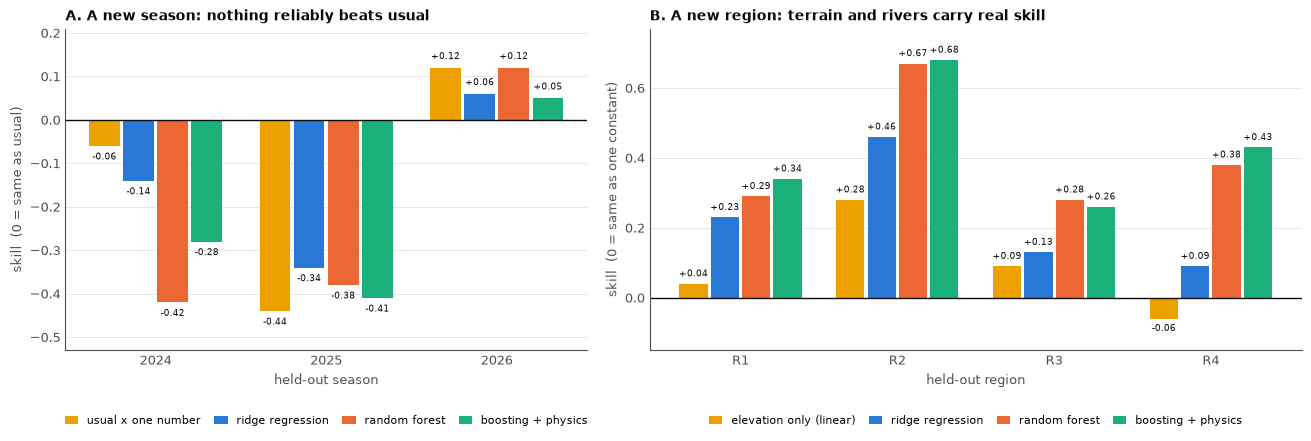

In [5]:
def bars(ax, T, rows, colors, title, ref_label):
    folds, n = list(T.columns), len(rows)
    width = 0.8 / n
    for i, (r, c) in enumerate(zip(rows, colors)):
        x = np.arange(len(folds)) + (i - (n - 1) / 2) * width
        v = T.loc[r].values.astype(float)
        ax.bar(x, v, width * 0.9, color=c, label=r)
        for xi, vi in zip(x, v):
            ax.text(xi, vi + (0.015 if vi >= 0 else -0.015), f"{vi:+.2f}", ha="center", va="bottom" if vi >= 0 else "top", fontsize=6.5, color=INK)
    ax.axhline(0, color=INK, lw=1)
    ax.set_xticks(range(len(folds))); ax.set_xticklabels(folds); ax.tick_params(length=0)
    ax.set_title(title, loc="left"); ax.set_ylabel(f"skill  ({ref_label})"); ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    lo, hi = np.nanmin(T.loc[rows].values), np.nanmax(T.loc[rows].values)
    ax.set_ylim(min(lo, 0) - 0.09, max(hi, 0) + 0.09)

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.3), layout="constrained", gridspec_kw={"width_ratios": [1, 1.25]})
bars(a, A, ["usual x one number", "ridge regression", "random forest", "boosting + physics"], [YELLOW, BLUE, ORANGE, AQUA],
     "A. A new season: nothing reliably beats usual", "0 = same as usual")
bars(b, B, ["elevation only (linear)", "ridge regression", "random forest", "boosting + physics"], [YELLOW, BLUE, ORANGE, AQUA],
     "B. A new region: terrain and rivers carry real skill", "0 = same as one constant")
a.set_xlabel("held-out season"); b.set_xlabel("held-out region")
for ax_ in (a, b):
    ax_.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=4, fontsize=8, columnspacing=1.2, handlelength=1.2)
save(fig, "paper_fig3_skill_by_fold"); plt.show()

## Figure 4 · What the forest uses, and the effect of height

Left: how much the error on an unseen region grows when one input is shuffled (average over the held-out regions, from notebook 04). Right: the forest's average prediction as a square sits higher above the lowest ground nearby, for the model tested on region R1.

saved figures/paper_fig4_what_it_learned.png


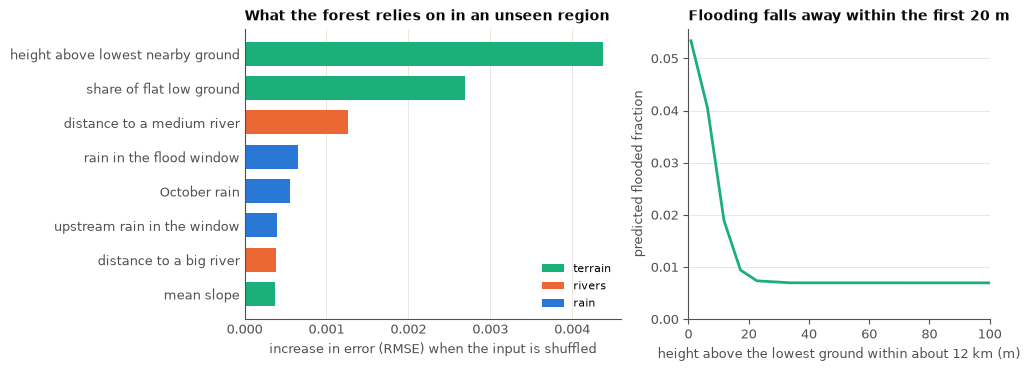

In [6]:
imp = pd.read_csv(RESULTS_DIR / "permutation_importance.csv", index_col=0)["B region hold-out"].sort_values().tail(8)
nice = {"rel_height": "height above lowest nearby ground", "low_share": "share of flat low ground", "dist_riv_1k_km": "distance to a medium river",
        "dist_riv_10k_km": "distance to a big river", "rain_window": "rain in the flood window", "rain_oct": "October rain",
        "up_rain_window": "upstream rain in the window", "slope_mean": "mean slope", "rain_sep": "September rain", "elev_std": "hilliness",
        "rain_early": "early-season rain", "log_up_area": "upstream area", "elev_mean": "mean elevation", "elev_p05": "lowest elevation",
        "rain_aug": "August rain", "max_7d": "wettest 7 days", "max_3d": "wettest 3 days", "max_1d": "wettest day",
        "heavy_days": "heavy-rain days", "up_rain_early": "upstream early rain", "up_coverage": "upstream rain coverage",
        "dist_riv_any_km": "distance to any river", "log_upland_nearest": "size of nearest river"}
group_col = lambda f: BLUE if ("rain" in f or f.startswith("max_") or f == "heavy_days") else ORANGE if ("riv" in f or "up_area" in f or "upland" in f) else AQUA

r0 = REGIONS[0]
tr, te = df[df.region != r0], df[df.region == r0]
rf = forest_for("B region", r0).fit(tr[FEATURES], tr[LABEL])
grid = np.linspace(0, 100, 41)
pd_ = partial_dependence(rf, te[FEATURES], ["rel_height"], custom_values={"rel_height": grid}) if "custom_values" in partial_dependence.__code__.co_varnames \
      else partial_dependence(rf, te[FEATURES], ["rel_height"], grid_resolution=60, percentiles=(0, 0.9))
gx = pd_["grid_values"][0] if "grid_values" in pd_ else pd_["values"][0]

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained", gridspec_kw={"width_ratios": [1.25, 1]})
a.barh([nice.get(f, f) for f in imp.index], imp.values, color=[group_col(f) for f in imp.index], height=0.7)
a.set_title("What the forest relies on in an unseen region", loc="left"); a.set_xlabel("increase in error (RMSE) when the input is shuffled")
a.xaxis.grid(True, color=GRID, lw=0.6); a.set_axisbelow(True); a.tick_params(length=0)
a.legend(handles=[Rectangle((0, 0), 1, 1, fc=c) for c in (AQUA, ORANGE, BLUE)], labels=["terrain", "rivers", "rain"], loc="lower right", fontsize=8)
b.plot(gx, pd_["average"][0], color=AQUA, lw=2)
b.set_xlim(0, min(100, gx.max())); b.set_ylim(0, None)
b.set_title("Flooding falls away within the first 20 m", loc="left")
b.set_xlabel("height above the lowest ground within about 12 km (m)"); b.set_ylabel("predicted flooded fraction")
b.yaxis.grid(True, color=GRID, lw=0.6); b.set_axisbelow(True)
save(fig, "paper_fig4_what_it_learned"); plt.show()

**Check before using the right-hand title:** it states that the drop happens within the first 20 m. If the curve above doesn't show that, change the title in the code to match what the curve shows.

## Figure 5 · 2026: where the forest was right and wrong

The forest is refitted on 2024 and 2025 with the settings notebook 04 chose, then asked about 2026. A square counts as flooded when at least 5% of it is underwater.

Below the figure the same counts are turned into two plain numbers: of the squares that flooded, how many were flagged (recall), and of the squares flagged, how many really flooded (precision). The same two numbers are printed for *usual*, so the forest can be compared with simply using the old maps.

saved figures/paper_fig5_error_map_2026.png


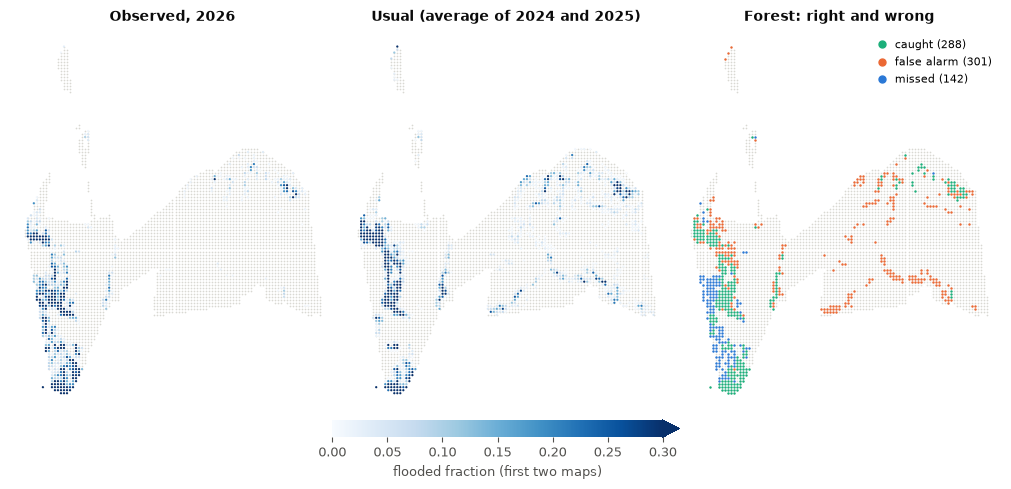

{'caught': 288, 'false alarm': 301, 'missed': 142}
Of 430 squares that flooded, the forest flagged 288 (67%, recall).
Of 589 squares it flagged, 288 really flooded (49%, precision).
Usual, same rule: flagged 284 of 430 flooded squares (66%); 50% of its flags were right.


In [7]:
s = YEARS[-1]; a_, b_ = [o for o in YEARS if o != s]
tr, te = df[df.season.isin([a_, b_])].copy(), df[df.season == s].copy()
tr["usual"] = np.where(tr.season == a_, tr.cell_id.map(piv[b_]), tr.cell_id.map(piv[a_]))
te["usual"] = te.cell_id.map(piv[[a_, b_]].mean(axis=1)).values
XA = FEATURES + ["usual"]
rf = forest_for("A season", s).fit(tr[XA], tr[LABEL] - tr["usual"])
te["pred"] = np.clip(te["usual"] + rf.predict(te[XA]), 0, 1)
obs_f, pred_f = te[LABEL] >= EVENT, te["pred"] >= EVENT
kinds = [("caught", obs_f & pred_f, AQUA), ("false alarm", ~obs_f & pred_f, ORANGE), ("missed", obs_f & ~pred_f, BLUE)]

fig, ax = plt.subplots(1, 3, figsize=(10, 4.8), layout="constrained")
for a, col, title in zip(ax[:2], [LABEL, "usual"], [f"Observed, {s}", f"Usual (average of {a_} and {b_})"]):
    a.scatter(te.lon, te.lat, c=PALE, s=1.5, linewidths=0)
    w = te[te[col] > 0].sort_values(col)
    sc_ = a.scatter(w.lon, w.lat, c=w[col], s=2.5, cmap="Blues", vmin=0, vmax=0.3, linewidths=0); clean_map(a, title)
cb = fig.colorbar(sc_, ax=ax, shrink=0.35, location="bottom", pad=0.02, extend="max"); cb.set_label("flooded fraction (first two maps)"); cb.outline.set_visible(False)
ax[2].scatter(te.lon, te.lat, c=PALE, s=1.5, linewidths=0)
for name, m, c in kinds:
    ax[2].scatter(te.lon[m], te.lat[m], color=c, s=3, linewidths=0)
clean_map(ax[2], "Forest: right and wrong")
ax[2].legend(handles=[Line2D([], [], marker="o", ls="", color=c, markersize=5) for _, _, c in kinds],
             labels=[f"{n} ({int(m.sum())})" for n, m, _ in kinds], loc="upper right", fontsize=8, handletextpad=0.2)
save(fig, "paper_fig5_error_map_2026"); plt.show()
print({n: int(m.sum()) for n, m, _ in kinds})
hit, fa, miss = int((obs_f & pred_f).sum()), int((~obs_f & pred_f).sum()), int((obs_f & ~pred_f).sum())
print(f"Of {hit + miss} squares that flooded, the forest flagged {hit} ({hit / (hit + miss):.0%}, recall).")
print(f"Of {hit + fa} squares it flagged, {hit} really flooded ({hit / (hit + fa):.0%}, precision).")
u_f = te["usual"] >= EVENT
uh, ufa, um = int((obs_f & u_f).sum()), int((~obs_f & u_f).sum()), int((obs_f & ~u_f).sum())
print(f"Usual, same rule: flagged {uh} of {uh + um} flooded squares ({uh / (uh + um):.0%}); {uh / (uh + ufa):.0%} of its flags were right.")

## Figure 6 · Season totals under the original and the equal-coverage label

Each season's average flooding divided by the three-season average (1.0 = average), for the original label and for the label rebuilt as if every cell had been photographed exactly 5 times (notebook 06). The number of looks is printed under each season.

saved figures/paper_fig6_fair_label.png


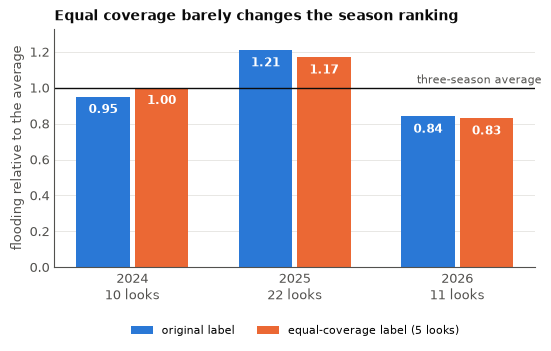

In [8]:
y1 = pd.read_csv(RESULTS_DIR / "y1_season_totals.csv").set_index("season")
fig, ax = plt.subplots(figsize=(5.4, 3.4), layout="constrained")
x = np.arange(len(y1))
for i, (col, c, lab) in enumerate([("original vs 3-season mean", BLUE, "original label"), ("fair vs 3-season mean", ORANGE, "equal-coverage label (5 looks)")]):
    v = y1[col].values
    ax.bar(x + (i - 0.5) * 0.36, v, 0.33, color=c, label=lab)
    for xi, vi in zip(x + (i - 0.5) * 0.36, v):
        ax.text(xi, vi - 0.04, f"{vi:.2f}", ha="center", va="top", fontsize=8.5, color="white", fontweight="bold")
ax.axhline(1, color=INK, lw=1); ax.text(len(x) - 0.48, 1.01, "three-season average", ha="right", va="bottom", fontsize=8, color=MUTED)
ax.set_xticks(x); ax.set_xticklabels([f"{s}\n{l:.0f} looks" for s, l in zip(y1.index, y1.looks)]); ax.tick_params(length=0)
ax.set_ylim(0, y1.iloc[:, -2:].values.max() + 0.12); ax.set_ylabel("flooding relative to the average")
ax.set_title("Equal coverage barely changes the season ranking", loc="left"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8)
ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
save(fig, "paper_fig6_fair_label"); plt.show()

**Check before using the title:** it states that the ranking barely changes. Confirm that with the numbers on the bars.

## Table 2 · Every stress test in one line

Numbers only, one value per held-out fold in the order shown. "Main" rows repeat Table 1 so each test can be read against it.

In [9]:
def fmt(v): return " / ".join(f"{float(x):+.2f}" for x in v)
x3 = pd.read_csv(RESULTS_DIR / "x3_region_robustness.csv")
x8 = pd.read_csv(RESULTS_DIR / "x8_small_network.csv")
y3 = pd.read_csv(RESULTS_DIR / "y3_results_by_label.csv"); y3["fold"] = y3["fold"].astype(str)
leak = pd.read_csv(RESULTS_DIR / "leakage_demo.csv")
x6 = pd.read_csv(RESULTS_DIR / "x6_quantile_coverage.csv"); x7 = pd.read_csv(RESULTS_DIR / "x7_unusual_inputs.csv")
sens = pd.read_csv(RESULTS_DIR / "label_sensitivity.csv", header=[0, 1], index_col=0)
x4w = lambda sch, m: x4[x4.scheme.str.startswith(sch) & (x4.method == m)].skill.values
fair = lambda sch, m: y3[(y3.scheme == sch) & (y3.method == m) & y3.label.str.startswith("fair (5")].value.values
p1 = sens["1-pass rule"].astype(float)
net = lambda sch: " / ".join(f"{a:+.1f} to {b:+.1f}" for a, b in x8[x8.scheme.str.startswith(sch)][["network_min", "network_max"]].values)
x9 = pd.read_csv(RESULTS_DIR / "x9_region_bootstrap.csv")
rng9 = lambda lo, hi: " / ".join(f"{a:+.2f} to {b:+.2f}" for a, b in x9[[lo, hi]].values)
seasons, regs = " / ".join(map(str, YEARS)), " / ".join(REGIONS)

T2 = pd.DataFrame([
 ("Season hold-out: forest skill vs usual", seasons, "main result", fmt(A.loc["random forest"])),
 ("", "", "history matched between training and test", fmt(x1.loc["forest (history-matched)"])),
 ("", "", "usual x one number (no rain, no terrain)", fmt(x1.loc["shrunken usual"])),
 ("", "", "gradient boosting", fmt(x4w("A", "boosting"))),
 ("", "", "boosting with physics constraints", fmt(x4w("A", "boosting + physics"))),
 ("", "", "small neural network, 5 random starts (lowest to highest)", net("A")),
 ("", "", "equal-coverage label (5 looks)", fmt(fair("A season", "skill: forest"))),
 ("", "", "1-pass label rule", fmt(1 - (p1.loc["forest"] / p1.loc["usual"]) ** 2)),
 ("Region hold-out: forest skill vs one constant", regs, "main result", fmt(B.loc["random forest"])),
 ("", "", "main result, 95% range (50 km block bootstrap)", rng9("vs_constant_low", "vs_constant_high")),
 ("", "", "forest against the best simple baseline in each region", fmt(x9.skill_vs_best_simple)),
 ("", "", "the same, 95% range (50 km block bootstrap)", rng9("vs_best_low", "vs_best_high")),
 ("", "", "10 km buffer, one fixed forest setting (reference for the next three rows)", fmt(x3[x3.setup == "basins, 10 km buffer"].forest_skill_vs_constant)),
 ("", "", "25 km buffer", fmt(x3[x3.setup == "basins, 25 km buffer"].forest_skill_vs_constant)),
 ("", "", "50 km buffer", fmt(x3[x3.setup == "basins, 50 km buffer"].forest_skill_vs_constant)),
 ("", "", "regions drawn by k-means instead of basins (K1 to K4)", fmt(x3[x3.setup.str.startswith("k-means")].forest_skill_vs_constant)),
 ("", "", "boosting with physics constraints", fmt(x4w("B", "boosting + physics"))),
 ("", "", "small neural network, 5 random starts (lowest to highest)", net("B")),
 ("", "", "equal-coverage label (5 looks)", fmt(fair("B region", "skill: forest"))),
 ("Random split instead of region hold-out", "forest RMSE", "random 5-fold / region hold-out", " / ".join(f"{v:.3f}" for v in leak.forest_RMSE)),
 ("Worst-case bound (90th percentile)", seasons, "share of flooded squares above it (10% if honest)", " / ".join(f"{v:.0%}" for v in x6.above_q90_flooded)),
 ("Rain unlike the training seasons", seasons, "share of test squares flagged (1% if alike)", " / ".join(f"{v:.0%}" for v in x7.share_unlike_training)),
], columns=["result", "folds", "test", "value per fold"])
T2.to_csv(RESULTS_DIR / "paper_table2_stress_tests.csv", index=False)
pd.set_option("display.max_colwidth", 80); T2

,result,folds,test,value per fold
0,Season hold-out: forest skill vs usual,2024 / 2025 / 2026,main result,-0.42 / -0.38 / +0.12
1,,,history matched between training and test,-0.36 / -0.31 / +0.11
2,,,"usual x one number (no rain, no terrain)",-0.06 / -0.44 / +0.12
3,,,gradient boosting,-0.26 / -0.39 / +0.02
4,,,boosting with physics constraints,-0.28 / -0.41 / +0.05
5,,,"small neural network, 5 random starts (lowest to highest)",-5.9 to -2.0 / -1.6 to -1.3 / -0.5 to -0.0
6,,,equal-coverage label (5 looks),-0.44 / -0.39 / +0.07
7,,,1-pass label rule,-0.14 / -0.25 / +0.13
8,Region hold-out: forest skill vs one constant,R1 / R2 / R3 / R4,main result,+0.29 / +0.67 / +0.28 / +0.38
9,,,"main result, 95% range (50 km block bootstrap)",+0.26 to +0.31 / +0.56 to +0.80 / +0.17 to +0.63 / +0.21 to +0.52


## Summary

Six figures are in `figures/` (names starting with `paper_fig`) and the tables in `results/` (names starting with `paper_table`). The two "check before using the title" notes above are the only places where a figure states a conclusion in words, so those two titles must match what the figure shows.